In [1]:
import sys
import os
from gaussian_beam import *
from adjoint import *
from plot import *
import time
import shutil
from datetime import timedelta

In [2]:
path='default/delta_f_targ_0.05_f_init_0.045_ell_0_wl_1e-06_f_num_25_conic_-1_nr_1000_r_maxf_5_nzf_501_dz_0.02_steps_5000_lr_1e-10_delta_1_tol_0.01_sg_0_order_0.txt'
params=initialize_variables_from_file(path)

In [3]:
f_targ = params["f_targ"]  # focal length of lens
ell = 0  # order of Bessel J function
f_init = params["f_init"]  # initial mirror focal length
conic = params["conic"]

# Beam Parameters
wl = params["wl"]  # wavelength
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = params["f_num"]  # f#
w0 = f_init / (2 * fn)  # initial spot size
rmax = params["r_maxf"] * w0  # the max value of r
nr = params["nr"]  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = params["dz"]
nzf = params["nzf"]
zF = np.linspace(f_targ - dz, f_targ + dz, nzf)
fl = len(zF) // 2  # focal length index

# Guess parameters
OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
w_guess = 10**OoM  # guess for the spot size
steps = params["steps"]  # max number of steps algorithm is allowed
lr = params["lr"]  # learning rate
tol = params["tol"]  # tolerance
delta = params["delta"]

In [5]:
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)


In [6]:
phi_I = 1j * np.exp(-((r / w0) ** 2))
zm_t = create_starting_optic(r, 2 * f_targ)  # target mirror
ftf_t = forward_propagation(
    w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_t
)  # Target profile defined using target mirror

a_n = create_initial_coeff(rmax, 2 * f_init)
rho = r / rmax
Z_fit = calc_Z(rho)
Z_plus = calc_Z_plus(Z_fit)

zm_r = generate_optic(a_n, Z_fit)

In [7]:
zm_c=create_starting_optic(r,2*f_init)

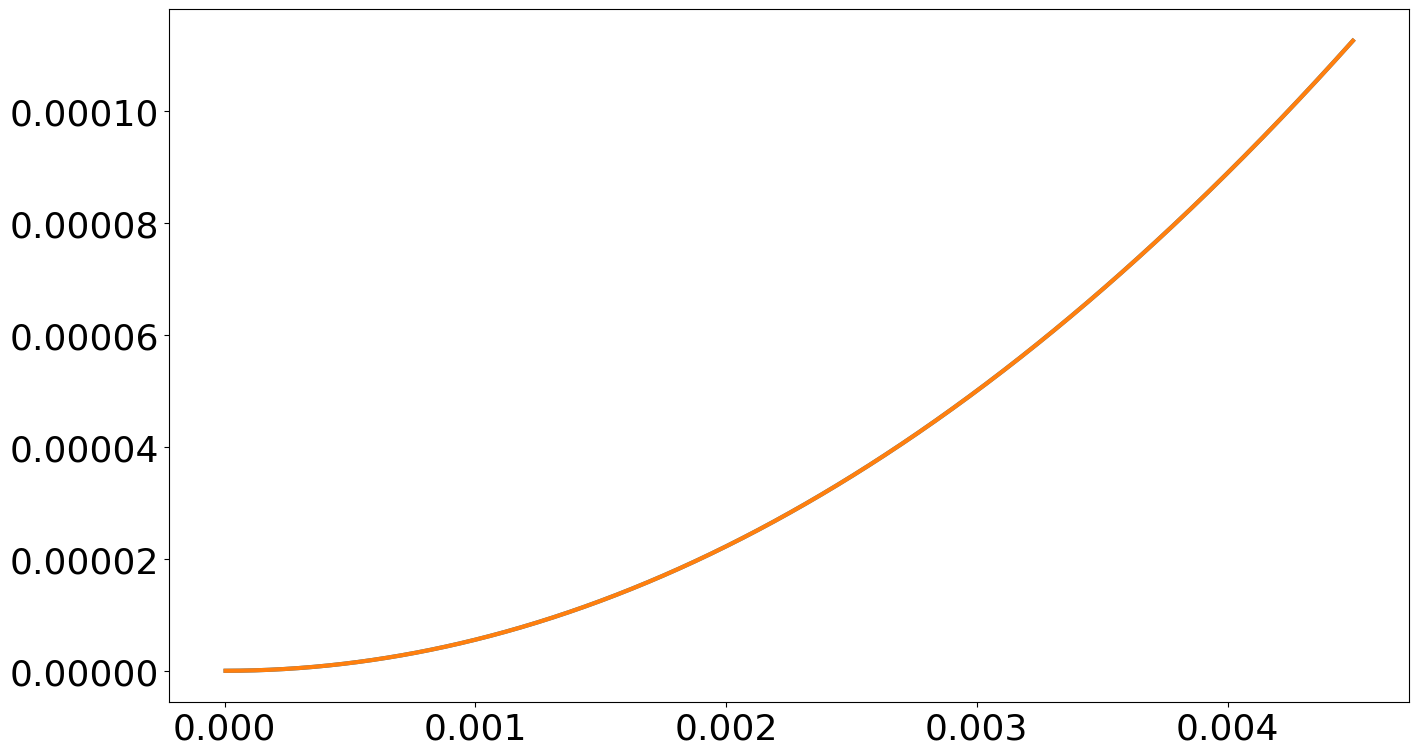

In [8]:
plt.plot(r,zm_r)
plt.plot(r,zm_c)
plt.show()